# Step 1: Data Cleaning & Quality Check

**Dataset:** `trends.csv` (Google Trends, 2001–2020)  
**Goal:** Load the raw data, check for missing values and duplicates, clean text spacing, add helpful columns, and save `data/trends_cleaned.csv`.


## 1. Load Libraries and Raw Data


In [1]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt

# Create output folders if they do not exist
os.makedirs("data", exist_ok=True)
os.makedirs("visualizations", exist_ok=True)

# Load the raw CSV file
df = pd.read_csv("trends.csv")
print("Dataset shape (rows, columns):", df.shape)
df.head()


Dataset shape (rows, columns): (26955, 5)


,location,year,category,rank,query
0,Global,2001,Consumer Brands,1,Nokia
1,Global,2001,Consumer Brands,2,Sony
2,Global,2001,Consumer Brands,3,BMW
3,Global,2001,Consumer Brands,4,Palm
4,Global,2001,Consumer Brands,5,Adobe


## 2. Check Data Types, Missing Values & Duplicates


In [2]:
print("Column data types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nExact duplicate rows:", df.duplicated().sum())


Column data types:
location    object
year         int64
category    object
rank         int64
query       object
dtype: object

Missing values per column:
location    0
year        0
category    0
rank        0
query       0
dtype: int64

Exact duplicate rows: 10


## 3. Clean the Data & Create Helpful Columns


In [3]:
# Make column names lowercase and replace spaces with underscores
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

# Fill any missing text values safely
df["location"] = df["location"].fillna("Unknown")
df["category"] = df["category"].fillna("Uncategorized")
df["query"] = df["query"].fillna("Unknown")

# Remove exact duplicate rows
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicates removed:", rows_before - len(df))

# Remove extra leading, trailing, and double spaces in text columns
for col in ["location", "category", "query"]:
    df[col] = df[col].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)

# Keep only valid year (2001-2025) and rank (1-5) numbers
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["rank"] = pd.to_numeric(df["rank"], errors="coerce")
df = df.dropna(subset=["year", "rank"])
df["year"] = df["year"].astype(int)
df["rank"] = df["rank"].astype(int)
df = df[(df["year"] >= 2001) & (df["year"] <= 2025)]
df = df[(df["rank"] >= 1) & (df["rank"] <= 5)].reset_index(drop=True)

# Standardize location formatting and add a lowercase category column
df["location"] = df["location"].str.title()
df["category_clean"] = df["category"].str.lower()

# Simple helper to detect which alphabet (writing script) a query uses
def detect_script(text):
    t = str(text)
    if re.search(r"[A-Za-z]", t):
        return "Latin"
    elif re.search(r"[\u4e00-\u9fff\u3040-\u30ff\uac00-\ud7af]", t):
        return "Chinese/CJK"
    elif re.search(r"[\u0400-\u04ff]", t):
        return "Cyrillic"
    elif re.search(r"[\u0600-\u06ff]", t):
        return "Arabic"
    elif re.search(r"[\u0e00-\u0e7f]", t):
        return "Thai"
    elif re.search(r"[\u0590-\u05ff]", t):
        return "Hebrew"
    elif re.search(r"[\u0370-\u03ff]", t):
        return "Greek"
    return "Other/Numeric"

# Add useful helper columns
df["script"] = df["query"].apply(detect_script)
df["is_global"] = df["location"] == "Global"
df["query_len"] = df["query"].str.len()
df["query_word_count"] = df["query"].str.split().str.len()

print("Clean dataset shape:", df.shape)
df.head()


Duplicates removed: 10


Clean dataset shape: (26945, 10)


,location,year,category,rank,query,category_clean,script,is_global,query_len,query_word_count
0,Global,2001,Consumer Brands,1,Nokia,consumer brands,Latin,True,5,1
1,Global,2001,Consumer Brands,2,Sony,consumer brands,Latin,True,4,1
2,Global,2001,Consumer Brands,3,BMW,consumer brands,Latin,True,3,1
3,Global,2001,Consumer Brands,4,Palm,consumer brands,Latin,True,4,1
4,Global,2001,Consumer Brands,5,Adobe,consumer brands,Latin,True,5,1


## 4. Check Query Length Outliers (IQR Method)


Upper limit: 29.0 characters
Outlier count: 911


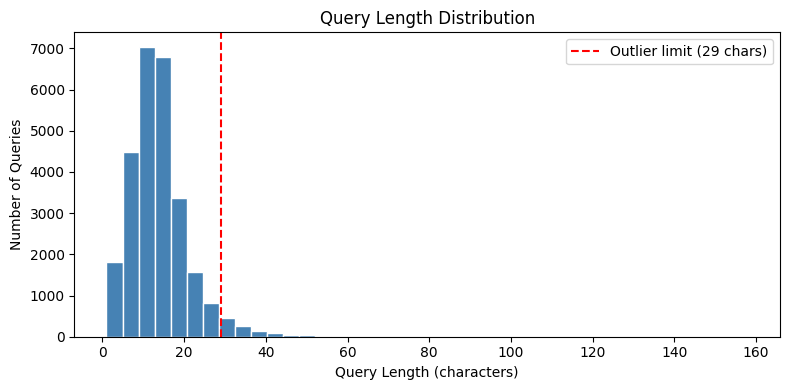

In [4]:
# Calculate the IQR upper limit for query length
q1 = df["query_len"].quantile(0.25)
q3 = df["query_len"].quantile(0.75)
upper_limit = q3 + 1.5 * (q3 - q1)

# Flag very long queries without deleting them (they are real titles/questions)
df["is_length_outlier"] = df["query_len"] > upper_limit
print(f"Upper limit: {upper_limit:.1f} characters")
print("Outlier count:", int(df["is_length_outlier"].sum()))

# Plot query length distribution
plt.figure(figsize=(8, 4))
plt.hist(df["query_len"], bins=40, color="steelblue", edgecolor="white")
plt.axvline(upper_limit, color="red", linestyle="--", label=f"Outlier limit ({upper_limit:.0f} chars)")
plt.title("Query Length Distribution")
plt.xlabel("Query Length (characters)")
plt.ylabel("Number of Queries")
plt.legend()
plt.tight_layout()
plt.savefig("visualizations/01_query_length_outliers.png", dpi=150)
plt.show()


## 5. Save the Cleaned Dataset


In [5]:
df.to_csv("data/trends_cleaned.csv", index=False)
print("Saved cleaned data to data/trends_cleaned.csv")
print("Final shape:", df.shape)


Saved cleaned data to data/trends_cleaned.csv
Final shape: (26945, 11)
